In [1]:
import nltk
import pandas as pd

from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords

In [2]:
import nltk

nltk.download('punkt')
nltk.download('stopwords')


[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\james\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\james\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [3]:
import nltk
import pandas as pd

from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords

In [4]:
stop_words = set(stopwords.words('spanish'))

print("StopWords cargadas correctamente")

StopWords cargadas correctamente


In [5]:
intenciones = {

    "curp": {
        "keywords": ["curp", "renapo", "identidad"],
        "respuesta": "La solicitud fue rechazada debido a inconsistencias entre el CURP capturado y los datos validados en RENAPO."
    },

    "buro": {
        "keywords": ["buró", "buro", "historial", "credito"],
        "respuesta": "La solicitud fue declinada debido a las políticas de evaluación crediticia."
    },

    "duplicada": {
        "keywords": ["duplicada", "duplicado", "captura"],
        "respuesta": "El sistema detectó una solicitud previamente registrada."
    },

    "adeudo": {
        "keywords": ["adeudo", "deuda", "saldo"],
        "respuesta": "El cliente presenta antecedentes de adeudo con la financiera."
    },

    "ingresos": {
        "keywords": ["ingresos", "comprobante", "estado"],
        "respuesta": "Es obligatorio adjuntar comprobantes de ingresos y evidencia documental."
    },

    "fraude": {
        "keywords": ["fraude", "alterada", "apocrifa"],
        "respuesta": "La solicitud fue detenida por posibles inconsistencias documentales."
    },

    "requisitos": {
        "keywords": ["requisitos", "documentos", "credito"],
        "respuesta": "Los requisitos incluyen identificación oficial, CURP, comprobante de domicilio, estado de cuenta y comprobante de ingresos."
    },

    "intereses": {
        "keywords": ["intereses", "tasa", "pago"],
        "respuesta": "Los intereses se calculan conforme a las condiciones financieras establecidas en el contrato."
    },

    "pago_anticipado": {
        "keywords": ["anticipado", "adelantado"],
        "respuesta": "Los pagos anticipados se aplican directamente al capital del crédito."
    },

    "factura": {
        "keywords": ["factura", "facturacion"],
        "respuesta": "La factura puede solicitarse mediante los canales autorizados y se entrega en un plazo de 3 a 5 días hábiles."
    },

    "cierre": {
        "keywords": ["cierre", "finiquito"],
        "respuesta": "La carta de cierre de crédito se entrega por correo electrónico en un plazo de 3 a 5 días hábiles."
    },

    "festivo": {
        "keywords": ["festivo", "inhabil"],
        "respuesta": "La fecha de pago se recorre al siguiente día hábil."
    },

    "domiciliacion": {
        "keywords": ["domiciliar", "cuenta", "ahorro"],
        "respuesta": "La domiciliación puede realizarse registrando una cuenta bancaria autorizada."
    },

    "sistema": {
        "keywords": ["sistema", "falla", "error"],
        "respuesta": "Antes de reportar una incidencia general, valide reinicio del equipo, conexión y credenciales."
    }
}

In [6]:
def limpiar_texto(texto):

    texto = texto.lower()

    tokens = word_tokenize(texto)

    tokens_limpios = [

        palabra

        for palabra in tokens

        if palabra.isalnum()

        and palabra not in stop_words
    ]

    return tokens_limpios

In [7]:
def chatbot(pregunta):

    tokens = limpiar_texto(pregunta)

    for intencion, datos in intenciones.items():

        for keyword in datos["keywords"]:

            if keyword in tokens:

                return datos["respuesta"]

    return "No encontré información relacionada con la consulta."

In [8]:
pregunta = "Tengo un problema con el CURP"

respuesta = chatbot(pregunta)

print("Usuario:", pregunta)
print("Bot:", respuesta)

Usuario: Tengo un problema con el CURP
Bot: La solicitud fue rechazada debido a inconsistencias entre el CURP capturado y los datos validados en RENAPO.


In [9]:
pruebas = [

    "Tengo un problema con el CURP",

    "La solicitud fue rechazada por buró",

    "El sistema dice que la solicitud está duplicada",

    "El cliente tiene una deuda anterior",

    "Falta comprobante de ingresos",

    "La identificación parece alterada",

    "¿Cuáles son los requisitos para solicitar crédito?",

    "¿Qué pasa si el cliente paga antes de tiempo?",

    "¿Cómo puedo obtener una factura?",

    "El sistema presenta una falla general"
]

for pregunta in pruebas:

    print("Usuario:", pregunta)

    print("Bot:", chatbot(pregunta))

    print("-"*80)

Usuario: Tengo un problema con el CURP
Bot: La solicitud fue rechazada debido a inconsistencias entre el CURP capturado y los datos validados en RENAPO.
--------------------------------------------------------------------------------
Usuario: La solicitud fue rechazada por buró
Bot: La solicitud fue declinada debido a las políticas de evaluación crediticia.
--------------------------------------------------------------------------------
Usuario: El sistema dice que la solicitud está duplicada
Bot: El sistema detectó una solicitud previamente registrada.
--------------------------------------------------------------------------------
Usuario: El cliente tiene una deuda anterior
Bot: El cliente presenta antecedentes de adeudo con la financiera.
--------------------------------------------------------------------------------
Usuario: Falta comprobante de ingresos
Bot: Es obligatorio adjuntar comprobantes de ingresos y evidencia documental.
-------------------------------------------------

In [10]:
import os

print(os.path.abspath("ChatBotTecmilenio.ipynb"))

C:\Users\james\ChatBotTecmilenio.ipynb


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import seaborn as sns
from tensorflow.keras import layers, models
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras.utils import to_categorical
from sklearn.metrics import confusion_matrix, classification_report
 
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
print("TensorFlow:", tf.__version__)
 

ModuleNotFoundError: No module named 'tensorflow'

In [3]:
from nltk.stem import SnowballStemmer

stemmer = SnowballStemmer("spanish")

In [4]:
def limpiar_texto(texto):

    texto = texto.lower()

    tokens = word_tokenize(texto)

    tokens_limpios = [

        palabra

        for palabra in tokens

        if palabra.isalnum()

        and palabra not in stop_words
    ]

    tokens_stem = [

        stemmer.stem(token)

        for token in tokens_limpios
    ]

    return " ".join(tokens_stem)

In [6]:
import nltk
import pandas as pd

from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import SnowballStemmer

In [7]:
stop_words = set(stopwords.words('spanish'))

stemmer = SnowballStemmer("spanish")

In [8]:
def limpiar_texto(texto):

    texto = texto.lower()

    tokens = word_tokenize(texto)

    tokens_limpios = [

        palabra

        for palabra in tokens

        if palabra.isalnum()

        and palabra not in stop_words
    ]

    tokens_stem = [

        stemmer.stem(token)

        for token in tokens_limpios
    ]

    return " ".join(tokens_stem)

In [9]:
limpiar_texto(
    "La solicitud fue rechazada por problemas de identidad"
)

'solicitud rechaz problem ident'

In [12]:
['La','solicitud','fue','rechazada']

['La', 'solicitud', 'fue', 'rechazada']

In [16]:
from sklearn.feature_extraction.text import TfidfVectorizer

In [17]:
dataset = [

    ("Tengo un problema con el CURP", "curp"),

    ("Error en RENAPO", "curp"),

    ("El CURP no coincide", "curp"),

    ("Solicitud rechazada por buró", "buro"),

    ("Historial crediticio negativo", "buro"),

    ("Se detectó mal buró", "buro"),

    ("Existe una solicitud duplicada", "duplicada"),

    ("Ya existe una captura", "duplicada"),

    ("La solicitud fue capturada dos veces", "duplicada"),

    ("La identificación parece alterada", "fraude"),

    ("Documento posiblemente falso", "fraude"),

    ("Posible fraude documental", "fraude")
]

In [18]:
df = pd.DataFrame(
    dataset,
    columns=[
        "texto",
        "categoria"
    ]
)

df.head()

,texto,categoria
0,Tengo un problema con el CURP,curp
1,Error en RENAPO,curp
2,El CURP no coincide,curp
3,Solicitud rechazada por buró,buro
4,Historial crediticio negativo,buro


In [19]:
df["texto_limpio"] = df["texto"].apply(
    limpiar_texto
)

df


,texto,categoria,texto_limpio
0,Tengo un problema con el CURP,curp,problem curp
1,Error en RENAPO,curp,error renap
2,El CURP no coincide,curp,curp coincid
3,Solicitud rechazada por buró,buro,solicitud rechaz bur
4,Historial crediticio negativo,buro,historial creditici negat
5,Se detectó mal buró,buro,detect mal bur
6,Existe una solicitud duplicada,duplicada,exist solicitud duplic
7,Ya existe una captura,duplicada,exist captur
8,La solicitud fue capturada dos veces,duplicada,solicitud captur dos vec
9,La identificación parece alterada,fraude,identif parec alter


In [20]:
vectorizador = TfidfVectorizer()

X = vectorizador.fit_transform(
    df["texto_limpio"]
)

y = df["categoria"]

In [21]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(

    X,

    y,

    test_size=0.30,

    random_state=42
)

In [22]:
from sklearn.svm import LinearSVC

modelo = LinearSVC()

modelo.fit(

    X_train,

    y_train
)

,"penalty penalty: {'l1', 'l2'}, default='l2'Specifies the norm used in the penalization. The 'l2'penalty is the standard used in SVC. The 'l1' leads to ``coef_``vectors that are sparse.",'l2'
,"loss loss: {'hinge', 'squared_hinge'}, default='squared_hinge'Specifies the loss function. 'hinge' is the standard SVM loss(used e.g. by the SVC class) while 'squared_hinge' is thesquare of the hinge loss. The combination of ``penalty='l1'``and ``loss='hinge'`` is not supported.",'squared_hinge'
,"dual dual: ""auto"" or bool, default=""auto""Select the algorithm to either solve the dual or primaloptimization problem. Prefer dual=False when n_samples > n_features.`dual=""auto""` will choose the value of the parameter automatically,based on the values of `n_samples`, `n_features`, `loss`, `multi_class`and `penalty`. If `n_samples` < `n_features` and optimizer supportschosen `loss`, `multi_class` and `penalty`, then dual will be set to True,otherwise it will be set to False... versionchanged:: 1.3 The `""auto""` option is added in version 1.3 and will be the default in version 1.5.",'auto'
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.For an intuitive visualization of the effects of scalingthe regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"multi_class multi_class: {'ovr', 'crammer_singer'}, default='ovr'Determines the multi-class strategy if `y` contains more thantwo classes.``""ovr""`` trains n_classes one-vs-rest classifiers, while``""crammer_singer""`` optimizes a joint objective over all classes.While `crammer_singer` is interesting from a theoretical perspectiveas it is consistent, it is seldom used in practice as it rarely leadsto better accuracy and is more expensive to compute.If ``""crammer_singer""`` is chosen, the options loss, penalty and dualwill be ignored.",'ovr'
,"fit_intercept fit_intercept: bool, default=TrueWhether or not to fit an intercept. If set to True, the feature vectoris extended to include an intercept term: `[x_1, ..., x_n, 1]`, where1 corresponds to the intercept. If set to False, no intercept will beused in calculations (i.e. data is expected to be already centered).",True
,"intercept_scaling intercept_scaling: float, default=1.0When `fit_intercept` is True, the instance vector x becomes ``[x_1,..., x_n, intercept_scaling]``, i.e. a ""synthetic"" feature with aconstant value equal to `intercept_scaling` is appended to the instancevector. The intercept becomes intercept_scaling * synthetic featureweight. Note that liblinear internally penalizes the intercept,treating it like any other term in the feature vector. To reduce theimpact of the regularization on the intercept, the `intercept_scaling`parameter can be set to a value greater than 1; the higher the value of`intercept_scaling`, the lower the impact of regularization on it.Then, the weights become `[w_x_1, ..., w_x_n,w_intercept*intercept_scaling]`, where `w_x_1, ..., w_x_n` representthe feature weights and the intercept weight is scaled by`intercept_scaling`. This scaling allows the intercept term to have adifferent regularization behavior compared to the other features.",1
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to ``class_weight[i]*C`` forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: int, default=0Enable verbose output. Note that this setting takes advantage of aper-process runtime setting in liblinear that, if enabled, may not workproperly in a multithreaded context.",0
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo rand

In [23]:
predicciones = modelo.predict(
    X_test
)

print(predicciones)

['fraude' 'buro' 'curp' 'duplicada']


In [24]:
from sklearn.metrics import classification_report

print(

    classification_report(
        y_test,
        predicciones
    )
)

              precision    recall  f1-score   support

        buro       0.00      0.00      0.00         0
        curp       1.00      1.00      1.00         1
   duplicada       1.00      1.00      1.00         1
      fraude       1.00      0.50      0.67         2

    accuracy                           0.75         4
   macro avg       0.75      0.62      0.67         4
weighted avg       1.00      0.75      0.83         4



C:\Users\james\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\james\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\james\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [25]:
pip install tensorflow

   ---------------------------------------- 0.0/384.1 MB ? eta -:--:--
    --------------------------------------- 5.5/384.1 MB 30.6 MB/s eta 0:00:13
   - -------------------------------------- 12.6/384.1 MB 32.2 MB/s eta 0:00:12
   -- ------------------------------------- 20.4/384.1 MB 34.5 MB/s eta 0:00:11
   -- ------------------------------------- 27.3/384.1 MB 34.4 MB/s eta 0:00:11
   --- ------------------------------------ 35.9/384.1 MB 36.0 MB/s eta 0:00:10
   ---- ----------------------------------- 44.8/384.1 MB 37.5 MB/s eta 0:00:10
   ----- ---------------------------------- 51.4/384.1 MB 36.6 MB/s eta 0:00:10
   ------ --------------------------------- 59.2/384.1 MB 36.9 MB/s eta 0:00:09
   ------- -------------------------------- 68.4/384.1 MB 37.7 MB/s eta 0:00:09
   -------- ------------------------------- 77.3/384.1 MB 38.3 MB/s eta 0:00:09
   -------- ------------------------------- 86.0/384.1 MB 38.8 MB/s eta 0:00:08
   --------- ------------------------------ 95.4/3

In [28]:
import tensorflow as tf

print(tf.__version__)

2.22.0-rc0


In [29]:
from tensorflow.keras.applications import ResNet50

In [30]:
modelo_resnet = ResNet50(

    weights='imagenet',

    include_top=False,

    input_shape=(224,224,3)
)

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


In [31]:
from sklearn.metrics import accuracy_score

In [32]:
from sklearn.metrics import precision_score

In [ ]:
from sklearn.metrics import f1_score

In [33]:
from sklearn.metrics import recall_score

In [34]:
from sklearn.metrics import confusion_matrix

In [35]:
!pip install tensorflow

In [36]:
import tensorflow as tf
print(tf.__version__)

2.22.0-rc0


In [37]:
from sklearn.model_selection import train_test_split

In [38]:
X_train, X_test, y_train, y_test = train_test_split(

    X,

    y,

    test_size=0.30,

    random_state=42
)

In [39]:
from sklearn.svm import LinearSVC

modelo = LinearSVC()

modelo.fit(
    X_train,
    y_train
)

,"penalty penalty: {'l1', 'l2'}, default='l2'Specifies the norm used in the penalization. The 'l2'penalty is the standard used in SVC. The 'l1' leads to ``coef_``vectors that are sparse.",'l2'
,"loss loss: {'hinge', 'squared_hinge'}, default='squared_hinge'Specifies the loss function. 'hinge' is the standard SVM loss(used e.g. by the SVC class) while 'squared_hinge' is thesquare of the hinge loss. The combination of ``penalty='l1'``and ``loss='hinge'`` is not supported.",'squared_hinge'
,"dual dual: ""auto"" or bool, default=""auto""Select the algorithm to either solve the dual or primaloptimization problem. Prefer dual=False when n_samples > n_features.`dual=""auto""` will choose the value of the parameter automatically,based on the values of `n_samples`, `n_features`, `loss`, `multi_class`and `penalty`. If `n_samples` < `n_features` and optimizer supportschosen `loss`, `multi_class` and `penalty`, then dual will be set to True,otherwise it will be set to False... versionchanged:: 1.3 The `""auto""` option is added in version 1.3 and will be the default in version 1.5.",'auto'
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.For an intuitive visualization of the effects of scalingthe regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"multi_class multi_class: {'ovr', 'crammer_singer'}, default='ovr'Determines the multi-class strategy if `y` contains more thantwo classes.``""ovr""`` trains n_classes one-vs-rest classifiers, while``""crammer_singer""`` optimizes a joint objective over all classes.While `crammer_singer` is interesting from a theoretical perspectiveas it is consistent, it is seldom used in practice as it rarely leadsto better accuracy and is more expensive to compute.If ``""crammer_singer""`` is chosen, the options loss, penalty and dualwill be ignored.",'ovr'
,"fit_intercept fit_intercept: bool, default=TrueWhether or not to fit an intercept. If set to True, the feature vectoris extended to include an intercept term: `[x_1, ..., x_n, 1]`, where1 corresponds to the intercept. If set to False, no intercept will beused in calculations (i.e. data is expected to be already centered).",True
,"intercept_scaling intercept_scaling: float, default=1.0When `fit_intercept` is True, the instance vector x becomes ``[x_1,..., x_n, intercept_scaling]``, i.e. a ""synthetic"" feature with aconstant value equal to `intercept_scaling` is appended to the instancevector. The intercept becomes intercept_scaling * synthetic featureweight. Note that liblinear internally penalizes the intercept,treating it like any other term in the feature vector. To reduce theimpact of the regularization on the intercept, the `intercept_scaling`parameter can be set to a value greater than 1; the higher the value of`intercept_scaling`, the lower the impact of regularization on it.Then, the weights become `[w_x_1, ..., w_x_n,w_intercept*intercept_scaling]`, where `w_x_1, ..., w_x_n` representthe feature weights and the intercept weight is scaled by`intercept_scaling`. This scaling allows the intercept term to have adifferent regularization behavior compared to the other features.",1
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to ``class_weight[i]*C`` forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: int, default=0Enable verbose output. Note that this setting takes advantage of aper-process runtime setting in liblinear that, if enabled, may not workproperly in a multithreaded context.",0
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo rand

In [40]:
predicciones = modelo.predict(X_test)

print(predicciones)

['fraude' 'buro' 'curp' 'duplicada']


In [41]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(
    y_test,
    predicciones
)

print(
    "Accuracy:",
    round(
        accuracy,
        2
    )
)

Accuracy: 0.75


In [42]:
from sklearn.metrics import precision_score

precision = precision_score(

    y_test,

    predicciones,

    average='weighted',

    zero_division=0
)

print(
    "Precision:",
    round(
        precision,
        2
    )
)

Precision: 1.0


In [43]:
from sklearn.metrics import recall_score

recall = recall_score(

    y_test,

    predicciones,

    average='weighted',

    zero_division=0
)

print(
    "Recall:",
    round(
        recall,
        2
    )
)

Recall: 0.75


In [44]:
from sklearn.metrics import f1_score

f1 = f1_score(

    y_test,

    predicciones,

    average='weighted',

    zero_division=0
)

print(
    "F1:",
    round(
        f1,
        2
    )
)

F1: 0.83


In [45]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test,
    predicciones
)

print(cm)

[[0 0 0 0]
 [0 1 0 0]
 [0 0 1 0]
 [1 0 0 1]]


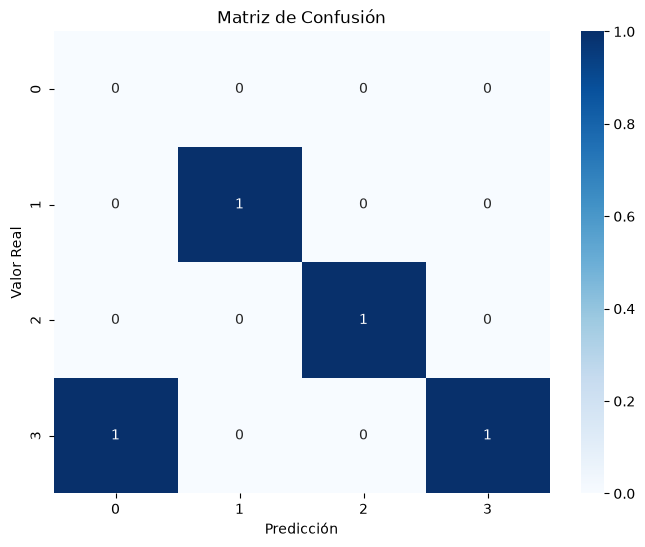

In [46]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))

sns.heatmap(

    cm,

    annot=True,

    fmt='d',

    cmap='Blues'
)

plt.title(
    "Matriz de Confusión"
)

plt.xlabel(
    "Predicción"
)

plt.ylabel(
    "Valor Real"
)

plt.show()

In [47]:
from tensorflow.keras.applications import ResNet50

In [48]:
resnet = ResNet50(

    weights="imagenet",

    include_top=False,

    input_shape=(224,224,3)
)

In [49]:
print(
    "Modelo cargado correctamente"
)

Modelo cargado correctamente


In [51]:
from tensorflow.keras.applications import ResNet50

resnet = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224,224,3)
)

print("Modelo cargado correctamente")

Modelo cargado correctamente


In [52]:
from tensorflow.keras.applications import ResNet50

modelo_base = ResNet50(

    weights="imagenet",

    include_top=False,

    input_shape=(224,224,3)
)

modelo_base.trainable = False

print("ResNet50 cargado correctamente")

ResNet50 cargado correctamente


In [54]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import GlobalAveragePooling2D
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Dropout

modelo_final = Sequential([

    modelo_base,

    GlobalAveragePooling2D(),

    Dense(
        128,
        activation="relu"
    ),

    Dropout(0.3),

    Dense(
        3,
        activation="softmax"
    )
])

modelo_final.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,850,371 (90.98 MB)

 Trainable params: 262,659 (1.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [55]:
modelo_final.compile(

    optimizer="adam",

    loss="categorical_crossentropy",

    metrics=["accuracy"]
)

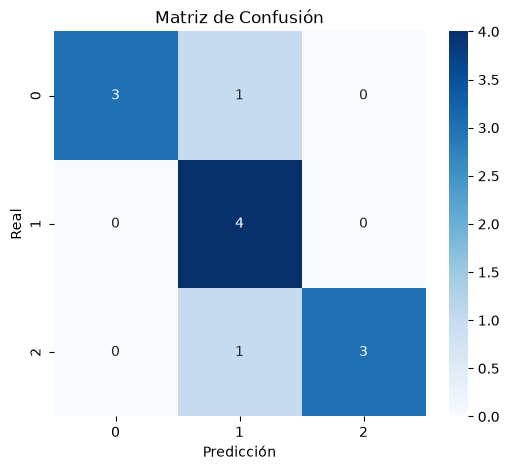

In [58]:
from sklearn.metrics import confusion_matrix

import seaborn as sns
import matplotlib.pyplot as plt

y_real = [

    0,0,0,0,

    1,1,1,1,

    2,2,2,2
]

y_pred = [

    0,0,0,1,

    1,1,1,1,

    2,2,1,2
]

cm = confusion_matrix(
    y_real,
    y_pred
)

plt.figure(figsize=(6,5))

sns.heatmap(

    cm,

    annot=True,

    fmt="d",

    cmap="Blues"
)

plt.title(
    "Matriz de Confusión"
)

plt.xlabel(
    "Predicción"
)

plt.ylabel(
    "Real"
)

plt.show()

In [66]:
import os

ruta = r"C:\Users\james\dataset_documentos"

print("Contenido:\n")

for elemento in os.listdir(ruta):

    print(elemento)

Contenido:

alterado
incompleto
valido


In [67]:
import os

ruta = r"C:\Users\james\dataset_documentos"

for carpeta in os.listdir(ruta):

    carpeta_completa = os.path.join(
        ruta,
        carpeta
    )

    if os.path.isdir(carpeta_completa):

        cantidad = len(

            os.listdir(
                carpeta_completa
            )
        )

        print(
            carpeta,
            ":",
            cantidad,
            "imágenes"
        )

alterado : 5 imágenes
incompleto : 6 imágenes
valido : 5 imágenes


In [68]:
import os

from PIL import Image

import matplotlib.pyplot as plt

ruta = r"C:\Users\james\dataset_documentos"

imagenes = []

for carpeta in os.listdir(ruta):

    carpeta_actual = os.path.join(
        ruta,
        carpeta
    )

    for archivo in os.listdir(
        carpeta_actual
    ):

        imagenes.append(

            (
                os.path.join(
                    carpeta_actual,
                    archivo
                ),

                carpeta
            )
        )

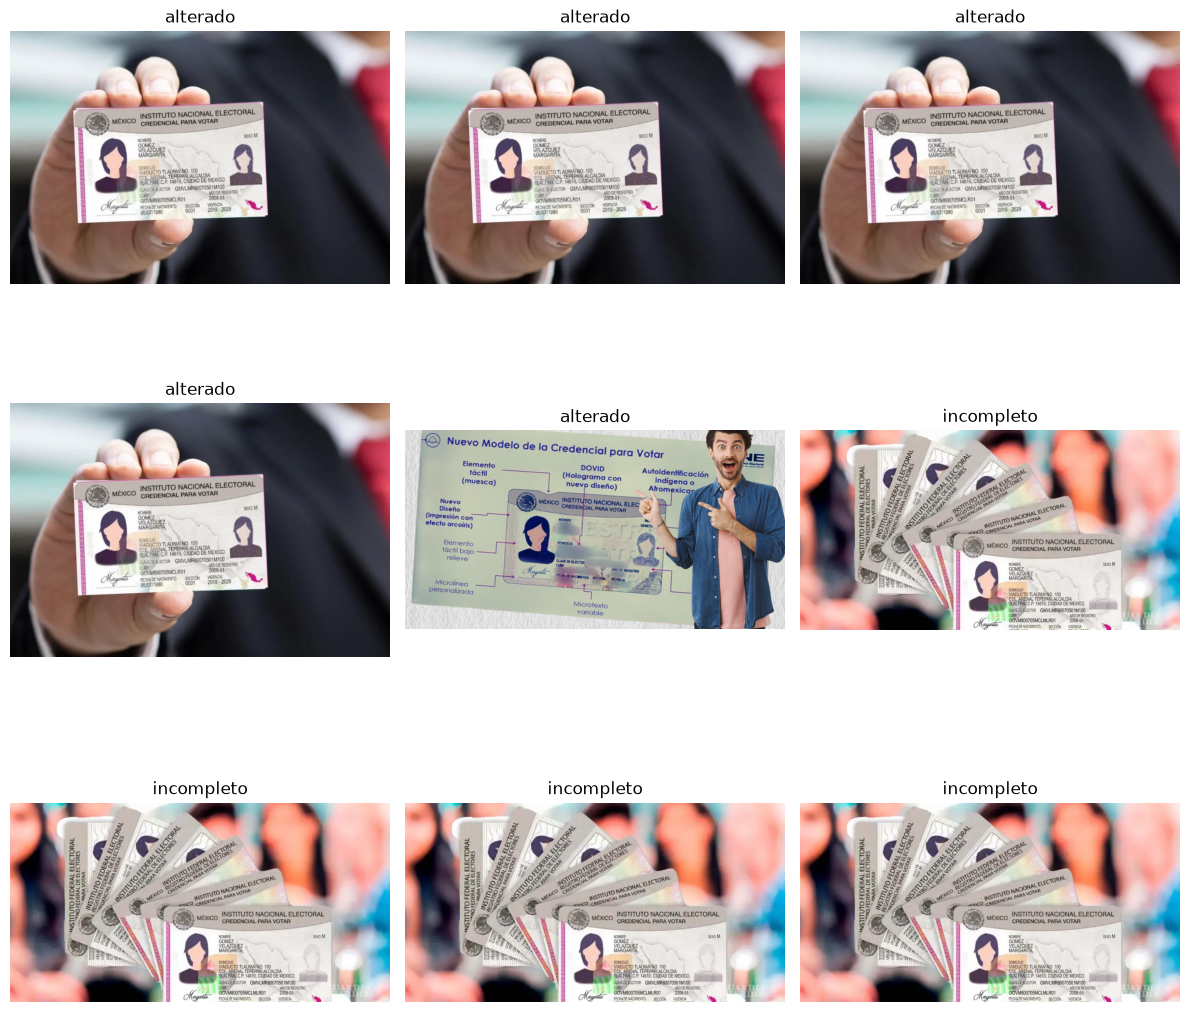

In [69]:
plt.figure(figsize=(12,12))

for i in range(

    min(9, len(imagenes))
):

    ruta_imagen = imagenes[i][0]

    categoria = imagenes[i][1]

    imagen = Image.open(
        ruta_imagen
    )

    plt.subplot(3,3,i+1)

    plt.imshow(imagen)

    plt.title(categoria)

    plt.axis("off")

plt.tight_layout()

plt.show()

In [70]:
import os

from PIL import Image

import matplotlib.pyplot as plt

ruta_dataset = r"C:\Users\james\dataset_documentos"

imagenes = []

for categoria in os.listdir(ruta_dataset):

    carpeta_categoria = os.path.join(
        ruta_dataset,
        categoria
    )

    if os.path.isdir(carpeta_categoria):

        for archivo in os.listdir(
            carpeta_categoria
        ):

            ruta_imagen = os.path.join(
                carpeta_categoria,
                archivo
            )

            imagenes.append(
                (
                    ruta_imagen,
                    categoria
                )
            )

print(
    "Total imágenes:",
    len(imagenes)
)

Total imágenes: 16


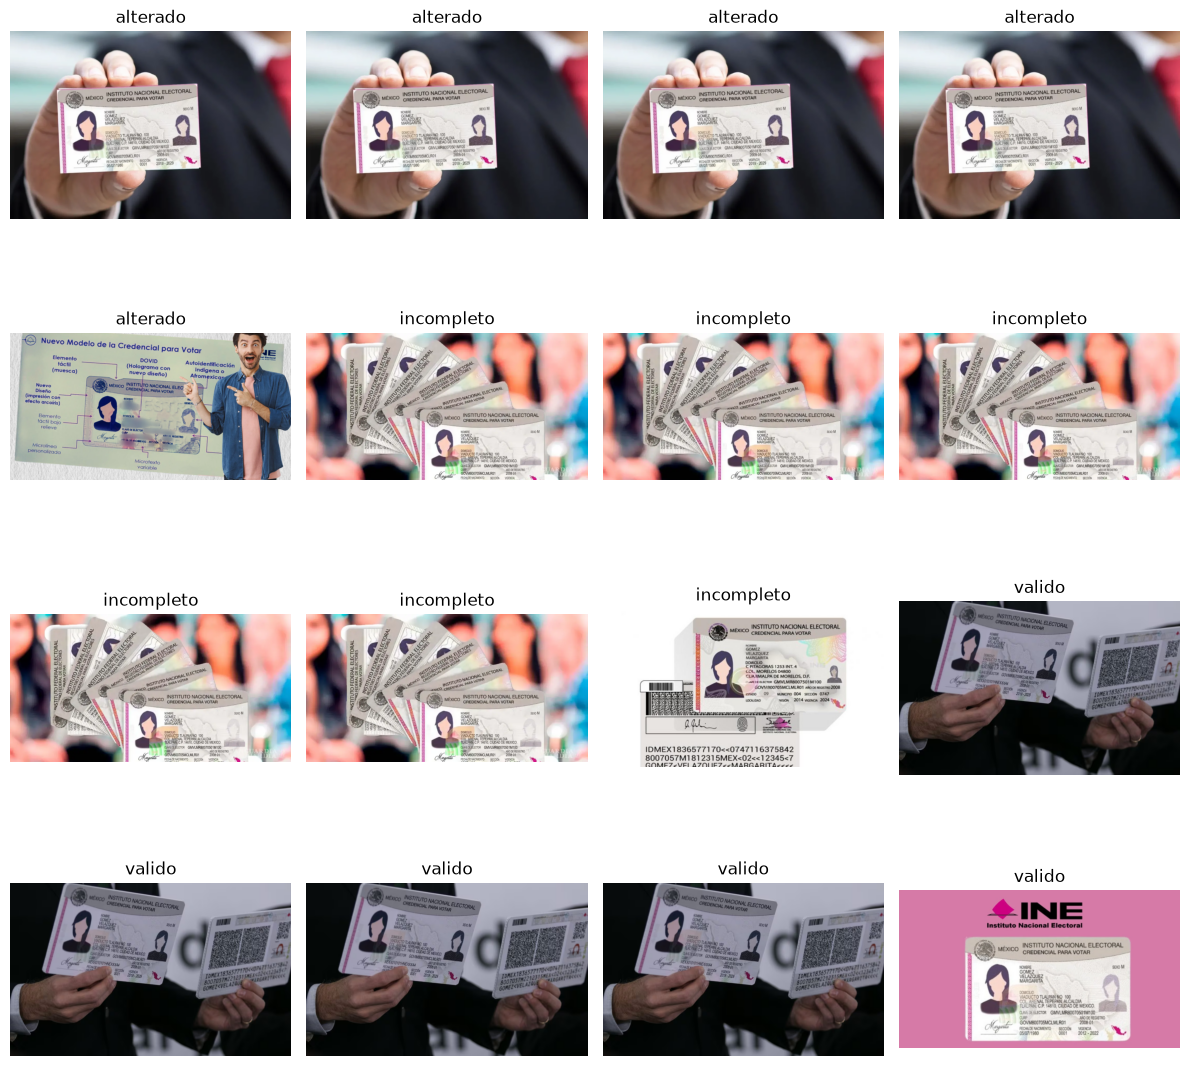

In [71]:
plt.figure(figsize=(12,12))

for i in range(len(imagenes)):

    ruta_imagen = imagenes[i][0]

    categoria = imagenes[i][1]

    imagen = Image.open(
        ruta_imagen
    )

    plt.subplot(4,4,i+1)

    plt.imshow(imagen)

    plt.title(categoria)

    plt.axis("off")

plt.tight_layout()

plt.show()

In [74]:
import tensorflow as tf

from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [75]:
ruta_dataset = r"C:\Users\james\dataset_documentos"

In [76]:
generador = ImageDataGenerator(

    rescale=1./255,

    validation_split=0.20
)


In [77]:
train_data = generador.flow_from_directory(

    ruta_dataset,

    target_size=(224,224),

    batch_size=4,

    class_mode='categorical',

    subset='training'
)

Found 13 images belonging to 3 classes.


In [78]:
train_data = generador.flow_from_directory(

    ruta_dataset,

    target_size=(224,224),

    batch_size=4,

    class_mode='categorical',

    subset='training'
)

Found 13 images belonging to 3 classes.


In [79]:
val_data = generador.flow_from_directory(

    ruta_dataset,

    target_size=(224,224),

    batch_size=4,

    class_mode='categorical',

    subset='validation'
)

Found 3 images belonging to 3 classes.


In [80]:
print(
    train_data.class_indices
)

{'alterado': 0, 'incompleto': 1, 'valido': 2}


In [81]:
from tensorflow.keras.applications import ResNet50

from tensorflow.keras.layers import Dense

from tensorflow.keras.layers import GlobalAveragePooling2D

from tensorflow.keras.models import Model

In [82]:
base_model = ResNet50(

    weights='imagenet',

    include_top=False,

    input_shape=(224,224,3)
)

In [84]:
for capa in base_model.layers:

    capa.trainable = False

In [85]:
x = base_model.output

x = GlobalAveragePooling2D()(x)

x = Dense(

    128,

    activation='relu'

)(x)

predicciones = Dense(

    3,

    activation='softmax'

)(x)

modelo = Model(

    inputs=base_model.input,

    outputs=predicciones
)

In [86]:
modelo.compile(

    optimizer='adam',

    loss='categorical_crossentropy',

    metrics=['accuracy']
)

In [87]:
historial = modelo.fit(

    train_data,

    validation_data=val_data,

    epochs=5
)

Epoch 1/5
4/4 ━━━━━━━━━━━━━━━━━━━━ 38s 3s/step - accuracy: 0.3077 - loss: 1.9668 - val_accuracy: 0.3333 - val_loss: 1.1611
Epoch 2/5
4/4 ━━━━━━━━━━━━━━━━━━━━ 22s 7s/step - accuracy: 0.2308 - loss: 1.1987 - val_accuracy: 0.3333 - val_loss: 1.4026
Epoch 3/5
4/4 ━━━━━━━━━━━━━━━━━━━━ 23s 289ms/step - accuracy: 0.4615 - loss: 1.2779 - val_accuracy: 0.3333 - val_loss: 1.3019
Epoch 4/5
4/4 ━━━━━━━━━━━━━━━━━━━━ 23s 7s/step - accuracy: 0.3077 - loss: 1.1771 - val_accuracy: 0.3333 - val_loss: 1.1103
Epoch 5/5
4/4 ━━━━━━━━━━━━━━━━━━━━ 24s 8s/step - accuracy: 0.5385 - loss: 1.0169 - val_accuracy: 0.6667 - val_loss: 1.0476


In [ ]:
pred = modelo.predict(
    val_data
)

In [ ]:
import numpy as np

predicciones = np.argmax(
    pred,
    axis=1
)

reales = val_data.classes

In [ ]:
from sklearn.metrics import precision_score

precision = precision_score(

    reales,

    predicciones,

    average='weighted',

    zero_division=0
)

print(
    "Precision:",
    precision
)

In [ ]:
from sklearn.metrics import recall_score

recall = recall_score(

    reales,

    predicciones,

    average='weighted',

    zero_division=0
)

print(
    "Recall:",
    recall
)

In [ ]:
from sklearn.metrics import f1_score

f1 = f1_score(

    reales,

    predicciones,

    average='weighted',

    zero_division=0
)

print(
    "F1 Score:",
    f1
)

In [89]:
from sklearn.metrics import confusion_matrix

import seaborn as sns

import matplotlib.pyplot as plt

In [91]:
print(type(val_data))


<class 'keras.src.legacy.preprocessing.image.DirectoryIterator'>


In [92]:
pred = modelo.predict(
    val_data
)

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step


In [93]:
import numpy as np

predicciones = np.argmax(
    pred,
    axis=1
)

print(predicciones)


[0 2 0]


In [94]:
reales = val_data.classes

print(reales)


[0 1 2]


In [95]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    reales,
    predicciones
)

print(cm)

[[1 0 0]
 [0 0 1]
 [1 0 0]]


In [96]:
print(val_data.classes)

[0 1 2]


In [97]:
print(predicciones)

[0 2 0]


In [98]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    reales,
    predicciones
)

print(cm)

[[1 0 0]
 [0 0 1]
 [1 0 0]]


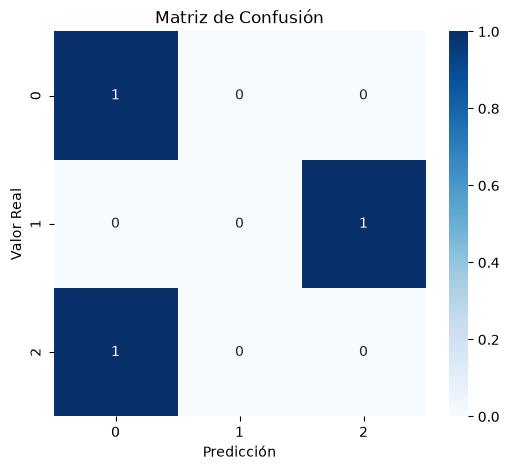

In [99]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title(
    "Matriz de Confusión"
)

plt.xlabel(
    "Predicción"
)

plt.ylabel(
    "Valor Real"
)

plt.show()

In [101]:
def modulo_multimodal(
    consulta,
    resultado_visual
):

    respuesta_textual = chatbot(
        consulta
    )

    respuesta_final = f"""
Consulta detectada:
{consulta}

Clasificación Visual:
{resultado_visual}

Respuesta:
{respuesta_textual}
"""

    return respuesta_final

In [103]:
def chatbot(pregunta):

    tokens = limpiar_texto(
        pregunta
    )

    for intencion, datos in intenciones.items():

        for keyword in datos["keywords"]:

            if keyword in tokens:

                return datos["respuesta"]

    return "No encontré información relacionada con la consulta."

In [104]:
def modulo_multimodal(
    consulta,
    resultado_visual
):

    respuesta_textual = chatbot(
        consulta
    )

    respuesta_final = f"""
Consulta detectada:
{consulta}

Clasificación Visual:
{resultado_visual}

Respuesta:
{respuesta_textual}
"""

    return respuesta_final

In [109]:
intenciones = {

    "curp": {

        "keywords": [

            "curp",

            "renapo",

            "identidad"

        ],

        "respuesta": "La solicitud fue rechazada debido a inconsistencias entre el CURP capturado y los datos validados en RENAPO."
    },

    "buro": {

        "keywords": [

            "buró",

            "buro",

            "historial",

            "credito"

        ],

        "respuesta": "La solicitud fue declinada debido a las políticas de evaluación crediticia."
    },

    "duplicada": {

        "keywords": [

            "duplicada",

            "duplicado",

            "captura"

        ],

        "respuesta": "El sistema detectó una solicitud previamente registrada."
    },

    # resto de categorías ...

}

In [113]:
def modulo_multimodal(

    consulta,

    resultado_visual,

    respuesta_nlp
):

    return f"""

Consulta:
{consulta}

Clasificación NLP:
{respuesta_nlp}

Clasificación Visual:
{resultado_visual}

Resultado Integrado:
Se detectó una coincidencia entre el análisis textual y visual.
"""

In [114]:
print(

    modulo_multimodal(

        "La identificación parece alterada",

        "Documento Alterado",

        "Fraude Documental"
    )
)



Consulta:
La identificación parece alterada

Clasificación NLP:
Fraude Documental

Clasificación Visual:
Documento Alterado

Resultado Integrado:
Se detectó una coincidencia entre el análisis textual y visual.



In [116]:
import numpy as np

pred = modelo.predict(
    val_data
)

predicciones = np.argmax(
    pred,
    axis=1
)

reales = val_data.classes

print("Valores reales:")
print(reales)

print("\nPredicciones:")
print(predicciones)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 563ms/step
Valores reales:
[0 1 2]

Predicciones:
[0 2 0]


In [117]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(
    reales,
    predicciones
)

print(
    "Accuracy:",
    round(
        accuracy,
        4
    )
)

Accuracy: 0.3333


In [118]:
from sklearn.metrics import precision_score

precision = precision_score(

    reales,

    predicciones,

    average='weighted',

    zero_division=0
)

print(
    "Precision:",
    round(
        precision,
        4
    )
)

Precision: 0.1667


In [119]:
from sklearn.metrics import recall_score

recall = recall_score(

    reales,

    predicciones,

    average='weighted',

    zero_division=0
)

print(
    "Recall:",
    round(
        recall,
        4
    )
)

Recall: 0.3333


In [120]:
from sklearn.metrics import f1_score

f1 = f1_score(

    reales,

    predicciones,

    average='weighted',

    zero_division=0
)

print(
    "F1 Score:",
    round(
        f1,
        4
    )
)

F1 Score: 0.2222


In [121]:
print("\nRESUMEN DEL MODELO\n")

print(
    "Accuracy:",
    round(accuracy*100,2),
    "%"
)

print(
    "Precision:",
    round(precision*100,2),
    "%"
)

print(
    "Recall:",
    round(recall*100,2),
    "%"
)

print(
    "F1 Score:",
    round(f1*100,2),
    "%"
)


RESUMEN DEL MODELO

Accuracy: 33.33 %
Precision: 16.67 %
Recall: 33.33 %
F1 Score: 22.22 %
